In [24]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [25]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
import os
from skimage.io import imread
from skimage.transform import resize
from keras.models import Sequential
from keras.layers import Conv2D,MaxPool2D,Flatten,Dense

In [26]:
#Training data
os.listdir('/content/drive/MyDrive/Maskdata')

['without_mask', 'with_mask']

In [27]:
#Testing data
os.listdir('/content/drive/MyDrive/Maskdatatest')

['with_mask', 'without_mask']

In [28]:
#Training data class without_mask
len(os.listdir('/content/drive/MyDrive/Maskdata/without_mask'))

1718

In [29]:
#Training data class with_mask
len(os.listdir('/content/drive/MyDrive/Maskdata/with_mask'))

1432

In [30]:
#Testing data class without mask
len(os.listdir('/content/drive/MyDrive/Maskdatatest/without_mask'))

42

In [31]:
#Testing data with mask
len(os.listdir('/content/drive/MyDrive/Maskdatatest/with_mask'))

60

In [32]:
#Sorting Training
train_data = sorted(os.listdir('/content/drive/MyDrive/Maskdata'))
train_data


['with_mask', 'without_mask']

In [33]:
#Sorting Testing
test_data = sorted(os.listdir('/content/drive/MyDrive/Maskdatatest'))
test_data

['with_mask', 'without_mask']

In [34]:
x_train = []
y_train = []
datadir = '/content/drive/MyDrive/Maskdata'

In [35]:
for i in train_data:
  print('Loading train data', i)
  path = os.path.join(datadir, i)
  for img in os.listdir(path):
      img_read = imread(os.path.join(path, img))
      img_res = resize(img_read, (150, 150, 3))
      x_train.append(img_res)
      y_train.append(train_data.index(i))
print('Loading completed')

Loading train data with_mask


/usr/local/lib/python3.13/dist-packages/PIL/Image.py:1047: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(


Loading train data without_mask
Loading completed


In [36]:
testdir = '/content/drive/MyDrive/Maskdatatest'
x_test = []
y_test = []


In [37]:
for i in test_data:
  print('Loading testing data',i)
  path = os.path.join(testdir,i)
  for img in os.listdir(path):
    img_read = imread(os.path.join(path,img))
    img_res = resize(img_read,(150,150,3))
    x_test.append(img_res)
    y_test.append(train_data.index(i))
print('Loading completed')

Loading testing data with_mask
Loading testing data without_mask
Loading completed


In [38]:
#Convert to array
x_train = np.array(x_train)
x_test = np.array(x_test)
y_train = np.array(y_train)
y_test = np.array(y_test)

In [39]:
#Architecture building
model = Sequential()
model.add(Conv2D(32,(3,3),input_shape = (150,150,3),activation = 'relu'))
model.add(MaxPool2D(2,2))
model.add(Flatten())
model.add(Dense(100,activation='relu'))
model.add(Dense(50,activation='relu'))
model.add(Dense(2,activation='softmax'))

/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [40]:
model.compile(optimizer='adam',loss='sparse_categorical_crossentropy',metrics=['accuracy'])

In [41]:
model.fit(x_train,y_train,epochs=100,batch_size = 100)

Epoch 1/100
32/32 ━━━━━━━━━━━━━━━━━━━━ 5s 72ms/step - accuracy: 0.6610 - loss: 1.4970
Epoch 2/100
32/32 ━━━━━━━━━━━━━━━━━━━━ 3s 42ms/step - accuracy: 0.8756 - loss: 0.3014
Epoch 3/100
32/32 ━━━━━━━━━━━━━━━━━━━━ 1s 41ms/step - accuracy: 0.9121 - loss: 0.2158
Epoch 4/100
32/32 ━━━━━━━━━━━━━━━━━━━━ 1s 41ms/step - accuracy: 0.9454 - loss: 0.1657
Epoch 5/100
32/32 ━━━━━━━━━━━━━━━━━━━━ 1s 41ms/step - accuracy: 0.9641 - loss: 0.1198
Epoch 6/100
32/32 ━━━━━━━━━━━━━━━━━━━━ 1s 42ms/step - accuracy: 0.9648 - loss: 0.1071
Epoch 7/100
32/32 ━━━━━━━━━━━━━━━━━━━━ 3s 45ms/step - accuracy: 0.9790 - loss: 0.0773
Epoch 8/100
32/32 ━━━━━━━━━━━━━━━━━━━━ 1s 42ms/step - accuracy: 0.9860 - loss: 0.0542
Epoch 9/100
32/32 ━━━━━━━━━━━━━━━━━━━━ 1s 41ms/step - accuracy: 0.9876 - loss: 0.0426
Epoch 10/100
32/32 ━━━━━━━━━━━━━━━━━━━━ 1s 42ms/step - accuracy: 0.9943 - loss: 0.0263
Epoch 11/100
32/32 ━━━━━━━━━━━━━━━━━━━━ 1s 41ms/step - accuracy: 0.9975 - loss: 0.0150
Epoch 12/100
32/32 ━━━━━━━━━━━━━━━━━━━━ 1s 41ms/step

In [42]:
model.evaluate(x_test,y_test,batch_size=50)

3/3 ━━━━━━━━━━━━━━━━━━━━ 1s 160ms/step - accuracy: 0.9608 - loss: 0.3164


[0.3164127469062805, 0.9607843160629272]

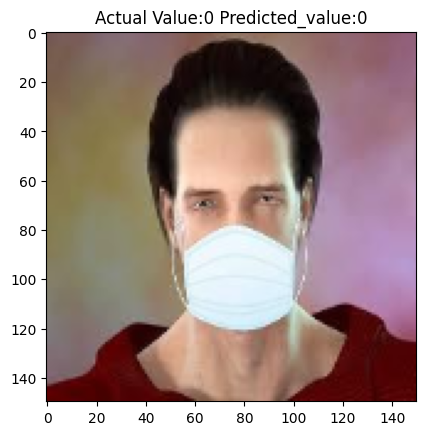

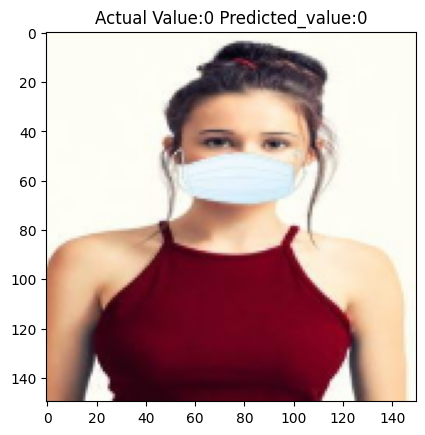

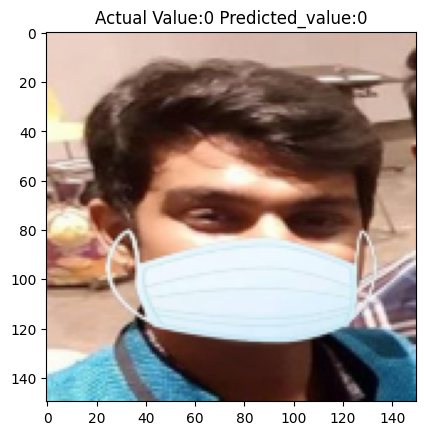

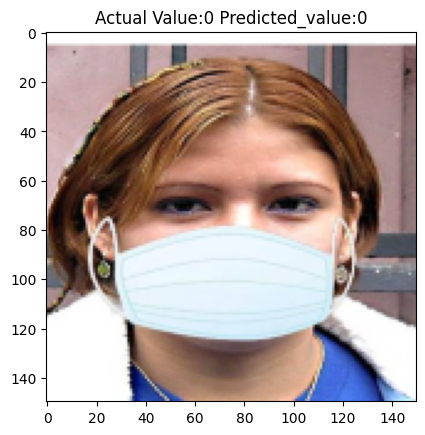

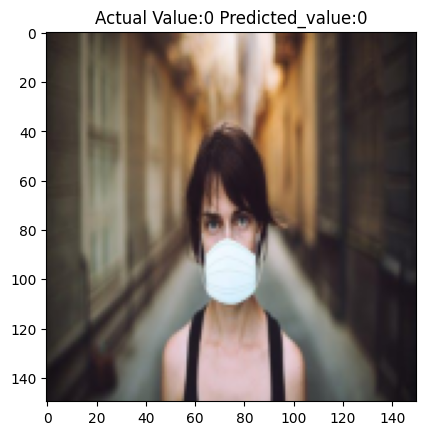

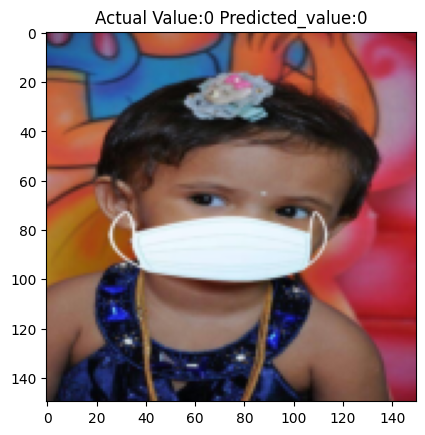

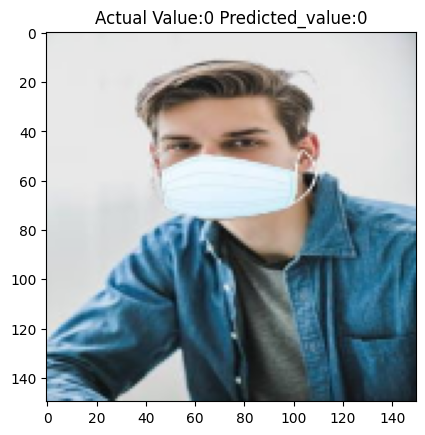

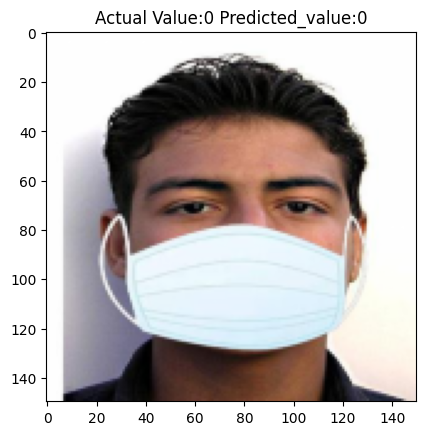

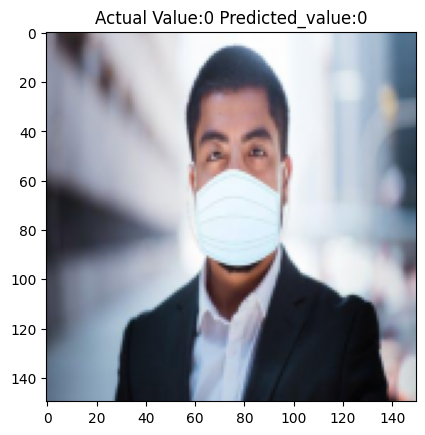

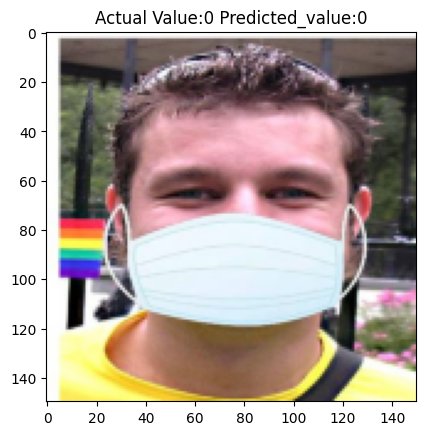

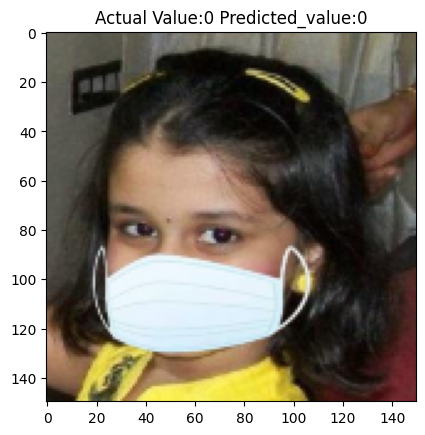

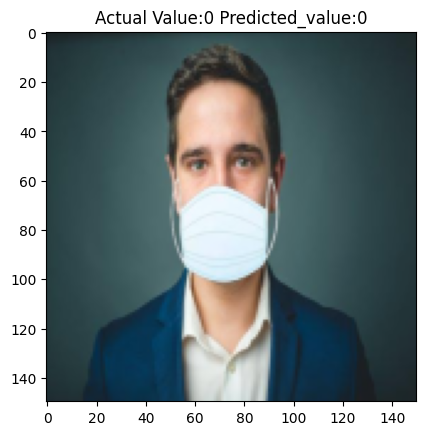

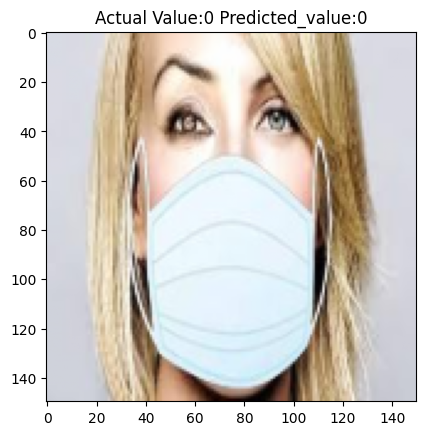

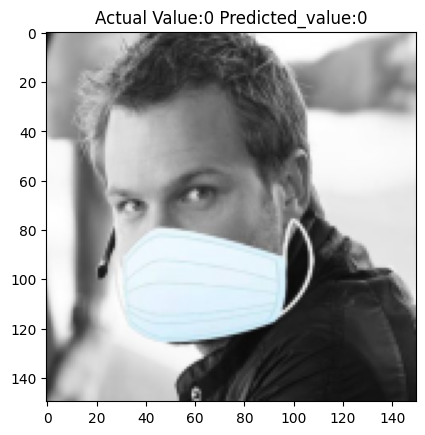

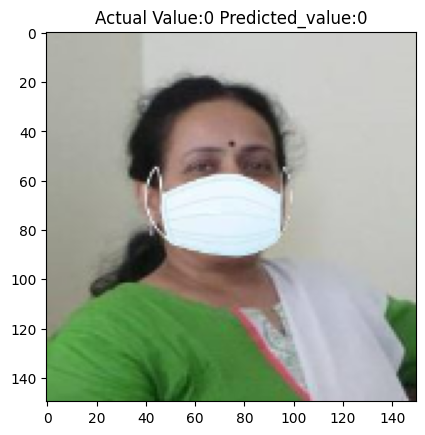

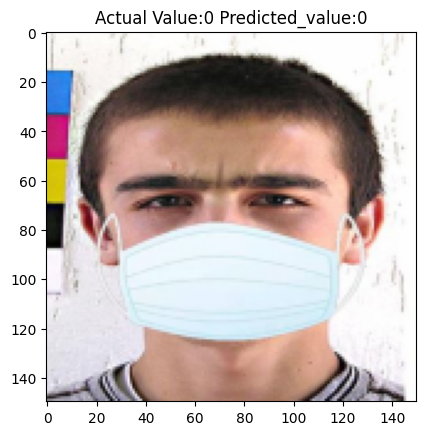

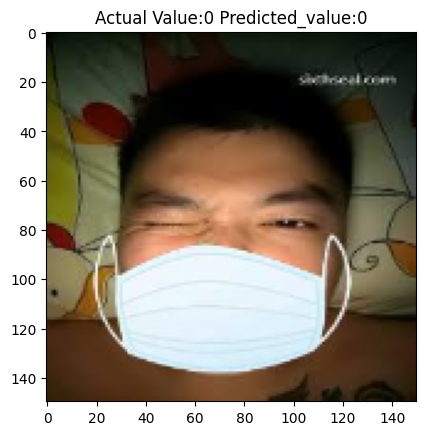

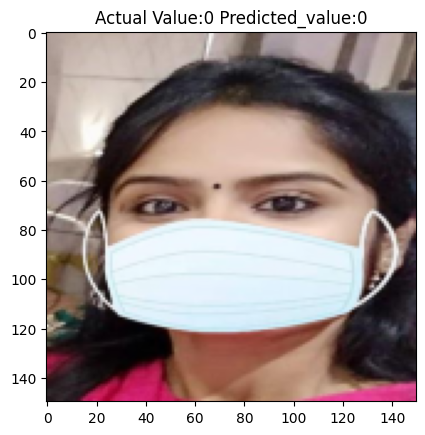

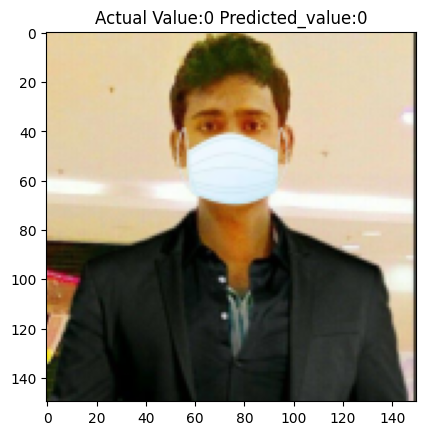

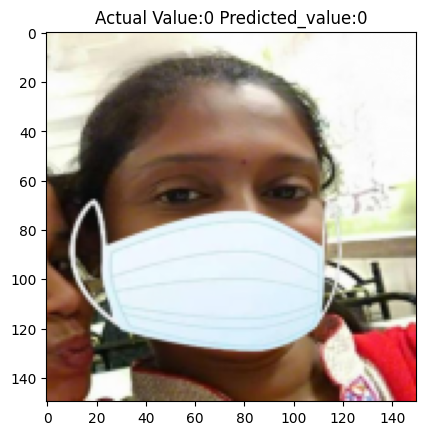

In [43]:
for i in range(10,30):
  y_pred = model.predict(x_test[i].reshape(1,150,150,3),verbose=0)
  output = np.argmax(y_pred)

  plt.imshow(x_test[i],cmap='gray')
  plt.title(f"Actual Value:{y_test[i]} Predicted_value:{output}")
  plt.show()

In [44]:
img = '/content/mask.avif'
img_read = imread(img)
img_resize = resize(img_read, (1,150, 150, 3))
output = model.predict(img_resize)
final_Output = np.argmax(output)
final_Output

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 46ms/step


np.int64(0)

In [ ]:
img = '/content/without_mask.jpg'
img_read = imread(img)
img_resize = resize(img_read, (1,150, 150, 3))
output = model.predict(img_resize)
final_Output = np.argmax(output)
final_Output

In [45]:
print(train_data)

['with_mask', 'without_mask']
